# Community Profiling & Interpretation

In [12]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 180)

BASE_DIR = Path.cwd()
SEMANTIC_DIR = BASE_DIR / "semantic_output"
CLEANING_DIR = BASE_DIR / "cleaning_output"

MEMBERSHIP_PATH_OVERRIDE = None
DATA_PATH_OVERRIDE = None

def find_file(filename, search_dirs):
    for folder in search_dirs:
        folder = Path(folder)
        candidate = folder / filename
        if candidate.exists():
            return candidate
    return None

MEMBERSHIP_PATH = (Path(MEMBERSHIP_PATH_OVERRIDE) if MEMBERSHIP_PATH_OVERRIDE
                   else find_file("community_membership_final.csv",
                                  [SEMANTIC_DIR, BASE_DIR, BASE_DIR.parent / "semantic_output"]))
DATA_PATH = (Path(DATA_PATH_OVERRIDE) if DATA_PATH_OVERRIDE
             else find_file("data_cleaned.csv",
                            [CLEANING_DIR, BASE_DIR, BASE_DIR.parent / "cleaning_output"]))

OUTPUT_DIR = SEMANTIC_DIR / "community_profiling"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder kerja :", BASE_DIR)
print("Membership  :", MEMBERSHIP_PATH)
print("Data bersih :", DATA_PATH)
print("Output      :", OUTPUT_DIR)
assert MEMBERSHIP_PATH is not None and MEMBERSHIP_PATH.exists(), (
    "community_membership_final.csv tidak ditemukan. Jalankan graph construction terlebih dahulu "
    "atau isi MEMBERSHIP_PATH_OVERRIDE.")
assert DATA_PATH is not None and DATA_PATH.exists(), (
    "data_cleaned.csv tidak ditemukan. Jalankan Cleaning Data terlebih dahulu "
    "atau isi DATA_PATH_OVERRIDE.")

N2_PATH_OVERRIDE = None
N2_PATH = (Path(N2_PATH_OVERRIDE) if N2_PATH_OVERRIDE
           else find_file("C_permutation_per_community.csv",
                          [SEMANTIC_DIR / "validation_06", SEMANTIC_DIR, BASE_DIR]))
assert N2_PATH is not None and N2_PATH.exists(), (
    "Hasil uji N2 tidak ditemukan. Jalankan baseline/null/bootstrap lebih dulu "
    "atau isi N2_PATH_OVERRIDE.")
print("Uji N2      :", N2_PATH)

Folder kerja : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A
Membership  : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\community_membership_final.csv
Data bersih : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\cleaning_output\data_cleaned.csv
Output      : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\community_profiling
Uji N2      : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\validation_06\C_permutation_per_community.csv


## 1. Muat data dan validasi penggabungan

In [13]:
nodes = pd.read_csv(MEMBERSHIP_PATH, low_memory=False)
df = pd.read_csv(DATA_PATH, low_memory=False)

node_required = ["node_id", "lokasi_key", "kelurahan", "kecamatan", "tahun",
                 "n_pengaduan", "komunitas"]
data_required = ["lokasi_key", "tahun", "kelompok_topik", "teks_embedding"]
missing_node = [c for c in node_required if c not in nodes.columns]
missing_data = [c for c in data_required if c not in df.columns]
assert not missing_node, f"Kolom node tidak tersedia: {missing_node}"
assert not missing_data, f"Kolom data bersih tidak tersedia: {missing_data}"

nodes["lokasi_key"] = nodes["lokasi_key"].astype(str)
df["lokasi_key"] = df["lokasi_key"].astype(str)
nodes["tahun"] = pd.to_numeric(nodes["tahun"], errors="raise").astype(int)
df["tahun"] = pd.to_numeric(df["tahun"], errors="raise").astype(int)
nodes["komunitas"] = pd.to_numeric(nodes["komunitas"], errors="raise").astype(int)

assert nodes["node_id"].is_unique
assert not nodes.duplicated(["lokasi_key", "tahun"]).any()
assert not df.duplicated(["no_tiket"]).any() if "no_tiket" in df.columns else True

key_cols = ["lokasi_key", "tahun"]
dfm = df.merge(nodes[key_cols + ["node_id", "kelurahan", "kecamatan", "komunitas"]],
               on=key_cols, how="left", suffixes=("", "_node"), validate="many_to_one")
assert dfm["komunitas"].notna().all(), (
    "Ada pengaduan yang tidak cocok dengan node komunitas. Periksa konsistensi data_cleaned dan Notebook 04.")

# Validasi bahwa jumlah pengaduan per node sama dengan n_pengaduan dari Notebook 04.
counts = dfm.groupby(key_cols).size().rename("n_data").reset_index()
check = nodes.merge(counts, on=key_cols, how="left")
check["n_data"] = check["n_data"].fillna(0).astype(int)
check["selisih"] = check["n_data"] - check["n_pengaduan"]
display(pd.DataFrame([{
    "jumlah_node": len(nodes),
    "jumlah_komunitas": nodes["komunitas"].nunique(),
    "jumlah_kelurahan": nodes["lokasi_key"].nunique(),
    "jumlah_pengaduan_tergabung": len(dfm),
    "node_dengan_jumlah_tidak_cocok": int((check["selisih"] != 0).sum()),
    "tahun": ", ".join(map(str, sorted(nodes["tahun"].unique())))
}]))
assert (check["selisih"] == 0).all(), (
    "Jumlah baris pengaduan per node berbeda dari n_pengaduan pada Notebook 04. "
    "Kemungkinan data_cleaned.csv yang dipakai bukan versi yang sama.")

print("Topik unik:", dfm["kelompok_topik"].nunique())
print("Rentang tahun:", sorted(dfm["tahun"].unique()))

,jumlah_node,jumlah_komunitas,jumlah_kelurahan,jumlah_pengaduan_tergabung,node_dengan_jumlah_tidak_cocok,tahun
0,459,10,153,33880,0,"2023, 2024, 2025"


Topik unik: 16
Rentang tahun: [np.int64(2023), np.int64(2024), np.int64(2025)]


## 2. Profil umum komunitas

Tabel ini merangkum ukuran komunitas pada dua tingkat: node (`kelurahan × tahun`) dan lokasi administratif unik. Volume pengaduan dihitung dari baris pengaduan yang tergabung.

In [14]:
profile_rows = []
for c, g in nodes.groupby("komunitas", sort=True):
    d = dfm[dfm["komunitas"] == c]
    yr_counts = g["tahun"].value_counts().sort_index()
    profile_rows.append({
        "komunitas": c,
        "jumlah_node": len(g),
        "jumlah_kelurahan_unik": g["lokasi_key"].nunique(),
        "jumlah_kecamatan": g["kecamatan"].nunique(),
        "jumlah_pengaduan": len(d),
        "rata_pengaduan_per_node": round(len(d) / len(g), 1),
        "tahun_2023_node": int(yr_counts.get(2023, 0)),
        "tahun_2024_node": int(yr_counts.get(2024, 0)),
        "tahun_2025_node": int(yr_counts.get(2025, 0)),
        "kecamatan_teratas": "; ".join(g["kecamatan"].value_counts().head(3).index.astype(str))
    })
community_profile = pd.DataFrame(profile_rows)
community_profile.to_csv(OUTPUT_DIR / "01_community_profile.csv", index=False, encoding="utf-8-sig")
display(community_profile)

,komunitas,jumlah_node,jumlah_kelurahan_unik,jumlah_kecamatan,jumlah_pengaduan,rata_pengaduan_per_node,tahun_2023_node,tahun_2024_node,tahun_2025_node,kecamatan_teratas
0,1,72,27,7,6533,90.7,24,24,24,Rungkut; Sukolilo; Mulyorejo
1,2,69,40,14,4082,59.2,12,21,36,Lakarsantri; Sukomanunggal; Wiyung
2,3,66,32,10,4242,64.3,28,24,14,Wonocolo; Wonokromo; Jambangan
3,4,65,27,8,4935,75.9,24,22,19,Tambaksari; Kenjeran; Bulak
4,5,53,23,7,2509,47.3,20,18,15,Tandes; Benowo; Pakal
5,6,42,18,8,3951,94.1,11,15,16,Genteng; Tegalsari; Sawahan
6,7,29,15,5,1321,45.6,15,8,6,Krembangan; Bubutan; Pabean Cantian
7,8,24,11,4,2058,85.8,10,8,6,Sawahan; Sukomanunggal; Tegalsari
8,9,23,11,4,3575,155.4,7,7,9,Gubeng; Tambaksari; Sukolilo
9,10,16,9,4,674,42.1,2,6,8,Pabean Cantian; Semampir; Simokerto


## 3. Profil topik per komunitas

`share_topik` adalah proporsi pengaduan dalam suatu komunitas. `share_global` adalah proporsi topik pada seluruh data. `lift` = `share_topik / share_global`; nilai di atas 1 menunjukkan topik relatif lebih menonjol dalam komunitas dibandingkan keseluruhan data.


In [15]:
topic_counts = pd.crosstab(dfm["komunitas"], dfm["kelompok_topik"])
topic_share = topic_counts.div(topic_counts.sum(axis=1), axis=0)
global_share = dfm["kelompok_topik"].value_counts(normalize=True)
topic_lift = topic_share.div(global_share, axis=1)

topic_long = (topic_counts.stack().rename("jumlah_pengaduan").reset_index()
              .rename(columns={"level_1": "kelompok_topik"}))
topic_long["share_komunitas"] = topic_long.apply(
    lambda r: topic_share.loc[r["komunitas"], r["kelompok_topik"]], axis=1)
topic_long["share_global"] = topic_long["kelompok_topik"].map(global_share)
topic_long["lift"] = topic_long["share_komunitas"] / topic_long["share_global"]
topic_long = topic_long.sort_values(["komunitas", "share_komunitas"], ascending=[True, False])
topic_long.to_csv(OUTPUT_DIR / "02_topic_profile_long.csv", index=False, encoding="utf-8-sig")

top_topics = (topic_long.sort_values(["komunitas", "share_komunitas"], ascending=[True, False])
              .groupby("komunitas").head(5))
display(top_topics[["komunitas", "kelompok_topik", "jumlah_pengaduan",
                    "share_komunitas", "share_global", "lift"]].round(3))

,komunitas,kelompok_topik,jumlah_pengaduan,share_komunitas,share_global,lift
3,1,Kebersihan & Lingkungan,1498,0.229,0.173,1.325
1,1,Infrastruktur Jalan & Saluran,1249,0.191,0.124,1.537
9,1,Pelayanan Kewilayahan,615,0.094,0.123,0.768
12,1,Perhubungan & Lalu Lintas,555,0.085,0.091,0.930
11,1,Penerangan Jalan & Traffic Light,554,0.085,0.092,0.924
17,2,Infrastruktur Jalan & Saluran,801,0.196,0.124,1.578
19,2,Kebersihan & Lingkungan,616,0.151,0.173,0.872
28,2,Perhubungan & Lalu Lintas,477,0.117,0.091,1.280
27,2,Penerangan Jalan & Traffic Light,439,0.108,0.092,1.172
25,2,Pelayanan Kewilayahan,427,0.105,0.123,0.854


### Ketidakpastian lift: bootstrap pada tingkat kelurahan

Bootstrap dilakukan dengan mengambil ulang unit `lokasi_key` (bukan tiket individual) agar pengelompokan pengaduan dalam kelurahan tetap diperhitungkan. Interval ini merupakan interval deskriptif untuk komposisi antarkelurahan. Karena topik dipilih berdasarkan lift pada data yang sama, interval ini **tidak** menghapus bias seleksi dan bukan uji konfirmasi independen.

In [16]:
BOOTSTRAP_B = 1000
BOOTSTRAP_SEED = 42
MIN_COUNT_FOR_LIFT_CI = 30

boot_df = dfm[["lokasi_key", "komunitas", "kelompok_topik"]].dropna().copy()
locs = boot_df["lokasi_key"].drop_duplicates().to_numpy()
n_loc = len(locs)
topics_all = sorted(boot_df["kelompok_topik"].unique())
communities_all = sorted(boot_df["komunitas"].unique())
C, T = len(communities_all), len(topics_all)

loc_idx = pd.Index(locs)
li = loc_idx.get_indexer(boot_df["lokasi_key"])
ci_ = pd.Index(communities_all).get_indexer(boot_df["komunitas"])
ti = pd.Index(topics_all).get_indexer(boot_df["kelompok_topik"])

cnt = np.zeros((n_loc, C, T))                    # kelurahan x komunitas x topik
np.add.at(cnt, (li, ci_, ti), 1)
cnt_flat = cnt.reshape(n_loc, -1)
obs_counts = cnt.sum(axis=0)
obs_den = obs_counts.sum(axis=1, keepdims=True)
obs_global = obs_counts.sum(axis=0) / obs_counts.sum()

pairs = [(a, b) for a in range(C) for b in range(T)
         if obs_counts[a, b] >= MIN_COUNT_FOR_LIFT_CI and obs_global[b] > 0]
boot_values = {p: [] for p in pairs}

rng = np.random.default_rng(BOOTSTRAP_SEED)
for _ in range(BOOTSTRAP_B):
    draw = rng.choice(locs, size=n_loc, replace=True)          # kelurahan diambil ulang
    mult = np.bincount(loc_idx.get_indexer(draw), minlength=n_loc).astype(float)
    ct = (mult @ cnt_flat).reshape(C, T)
    den = ct.sum(axis=1)
    g_share = ct.sum(axis=0) / ct.sum()
    for a, b in pairs:
        if den[a] > 0 and g_share[b] > 0:
            boot_values[(a, b)].append(ct[a, b] / den[a] / g_share[b])

ci_rows = []
for (a, b) in pairs:
    vals = np.asarray(boot_values[(a, b)], dtype=float)
    vals = vals[np.isfinite(vals)]
    ci_rows.append({
        "komunitas": int(communities_all[a]), "kelompok_topik": topics_all[b],
        "jumlah_pengaduan": int(obs_counts[a, b]),
        "lift": float((obs_counts[a, b] / obs_den[a, 0]) / obs_global[b]),
        "ci95_bawah": float(np.quantile(vals, 0.025)) if len(vals) else np.nan,
        "ci95_atas": float(np.quantile(vals, 0.975)) if len(vals) else np.nan,
        "n_bootstrap_valid": int(len(vals)),
    })
lift_bootstrap_ci = pd.DataFrame(ci_rows)
lift_bootstrap_ci.to_csv(OUTPUT_DIR / "09_topic_lift_bootstrap_kelurahan.csv",
                         index=False, encoding="utf-8-sig")
display(lift_bootstrap_ci.sort_values(["komunitas", "lift"], ascending=[True, False]).round(3))

,komunitas,kelompok_topik,jumlah_pengaduan,lift,ci95_bawah,ci95_atas,n_bootstrap_valid
13,1,Perumahan & Pertanahan,249,1.545,1.071,2.111,1000
1,1,Infrastruktur Jalan & Saluran,1249,1.537,1.245,1.804,1000
0,1,Banjir & Drainase,378,1.389,1.108,1.631,1000
3,1,Kebersihan & Lingkungan,1498,1.325,1.147,1.524,1000
6,1,Ketenagakerjaan,73,0.991,0.530,1.668,1000
...,...,...,...,...,...,...,...
139,10,Utilitas,39,1.138,0.652,1.845,1000
137,10,Penerangan Jalan & Traffic Light,66,1.067,0.833,1.333,1000
136,10,Pelayanan Kewilayahan,83,1.005,0.630,1.496,1000
133,10,Infrastruktur Jalan & Saluran,83,0.990,0.667,1.321,1000


### Visualisasi topik dominan

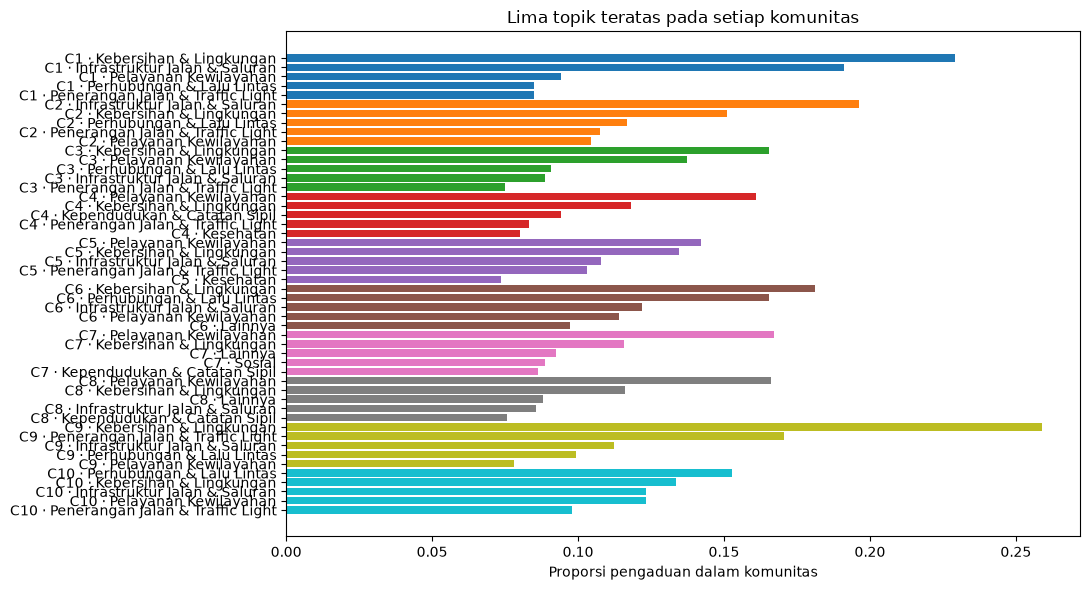

In [17]:
top_n = 5
plot_data = top_topics.copy()
fig, ax = plt.subplots(figsize=(11, 6))
for c in sorted(plot_data["komunitas"].unique()):
    g = plot_data[plot_data["komunitas"] == c]
    ax.barh([f"C{c} · {t}" for t in g["kelompok_topik"]],
            g["share_komunitas"], label=f"Komunitas {c}")
ax.set_xlabel("Proporsi pengaduan dalam komunitas")
ax.set_title("Lima topik teratas pada setiap komunitas")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_topik_dominan.png", dpi=160, bbox_inches="tight")
plt.show()

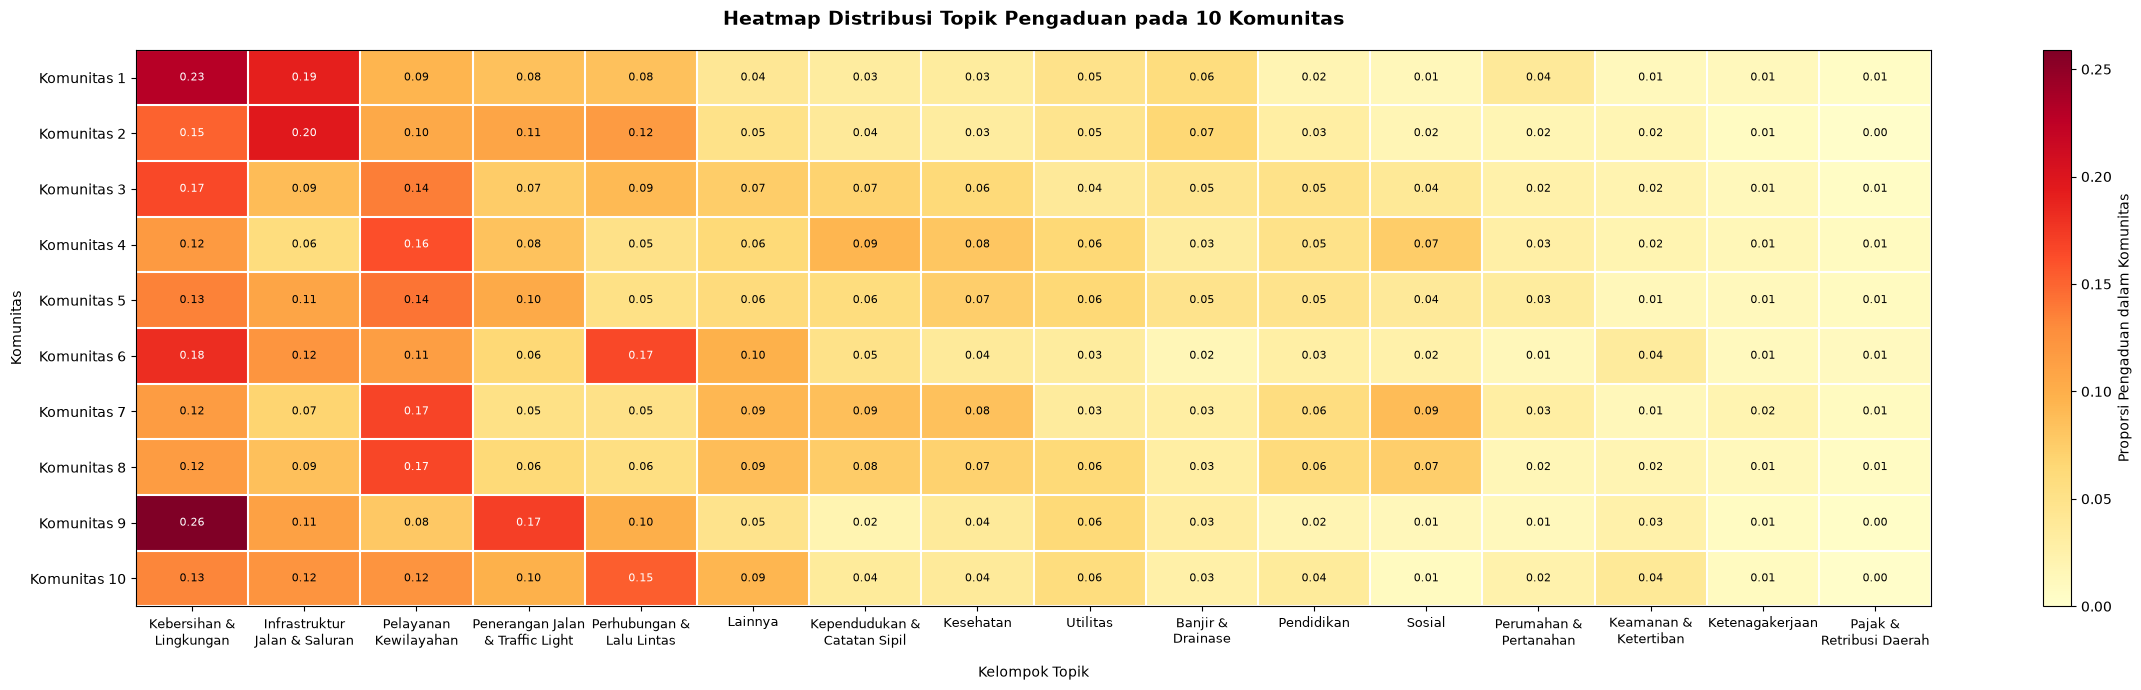

In [18]:
# HEATMAP PROFIL TOPIK PADA 10 KOMUNITAS
import matplotlib.pyplot as plt
import numpy as np
import textwrap


heatmap_data = topic_share.copy()

# Urutkan komunitas
heatmap_data = heatmap_data.sort_index()

# Urutkan topik berdasarkan proporsi global
topic_order = (
    dfm["kelompok_topik"]
    .value_counts(normalize=True)
    .index
    .tolist()
)

heatmap_data = heatmap_data.reindex(
    columns=topic_order,
    fill_value=0
)

# Ukuran gambar menyesuaikan jumlah topik
fig_width = max(11, len(heatmap_data.columns) * 1.5)

fig, ax = plt.subplots(
    figsize=(fig_width, 7)
)

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=heatmap_data.values.max()
)

# Label sumbu X dan Y
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))

ax.set_xticklabels(
    [
        "\n".join(textwrap.wrap(str(t), width=16))
        for t in heatmap_data.columns
    ],
    rotation=0,
    ha="center",
    fontsize=9
)

ax.set_yticklabels(
    [f"Komunitas {c}" for c in heatmap_data.index],
    fontsize=10
)

# Menampilkan nilai proporsi di setiap sel
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):

        value = heatmap_data.iloc[i, j]

        # Warna teks menyesuaikan intensitas sel
        text_color = (
            "white"
            if value > heatmap_data.values.max() * 0.55
            else "black"
        )

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(
    "Proporsi Pengaduan dalam Komunitas",
    rotation=90
)

ax.set_title(
    "Heatmap Distribusi Topik Pengaduan pada 10 Komunitas",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Kelompok Topik", labelpad=12)
ax.set_ylabel("Komunitas")

# Garis pemisah antar sel
ax.set_xticks(
    np.arange(-0.5, heatmap_data.shape[1], 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, heatmap_data.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.5
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "03_heatmap_profil_topik_komunitas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Dinamika pengaduan menurut tahun

Analisis ini menggunakan jumlah pengaduan individual per tahun dalam tiap komunitas. Perubahan jumlah dapat dipengaruhi volume pelaporan, perubahan kanal, maupun kondisi layanan; jangan langsung menyebutnya sebagai perubahan prevalensi masalah.

tahun,2023,2024,2025
komunitas,,,
1,2174,2226,2133
2,678,1312,2092
3,1924,1431,887
4,2341,1623,971
5,1077,816,616
6,1210,1342,1399
7,719,396,206
8,921,729,408
9,1085,1316,1174


tahun,2023,2024,2025
komunitas,,,
1,0.333,0.341,0.326
2,0.166,0.321,0.512
3,0.454,0.337,0.209
4,0.474,0.329,0.197
5,0.429,0.325,0.246
6,0.306,0.340,0.354
7,0.544,0.300,0.156
8,0.448,0.354,0.198
9,0.303,0.368,0.328


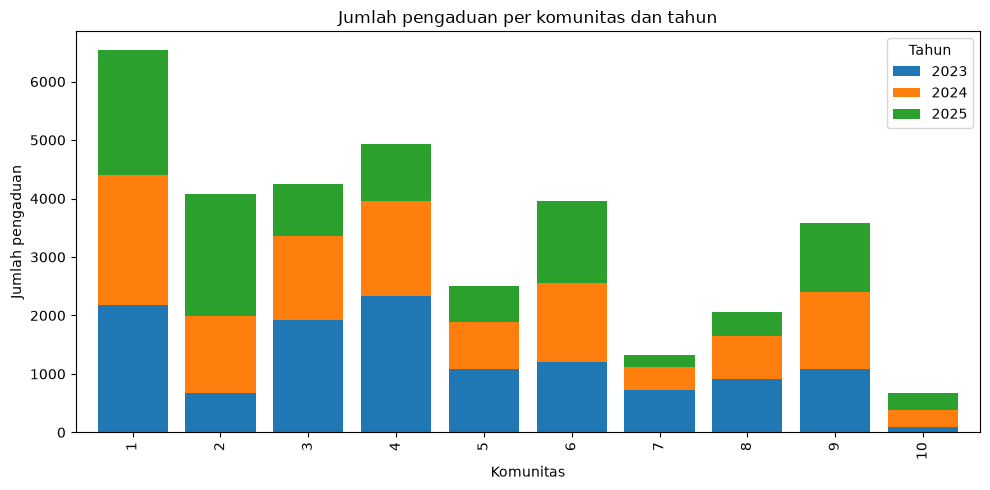

In [19]:
year_counts = pd.crosstab(dfm["komunitas"], dfm["tahun"])
year_counts.to_csv(OUTPUT_DIR / "04_complaints_by_year.csv", encoding="utf-8-sig")
year_share = year_counts.div(year_counts.sum(axis=1), axis=0)
display(year_counts)
display(year_share.round(3))

ax = year_counts.plot(kind="bar", stacked=True, figsize=(10, 5), width=0.8)
ax.set_xlabel("Komunitas")
ax.set_ylabel("Jumlah pengaduan")
ax.set_title("Jumlah pengaduan per komunitas dan tahun")
ax.legend(title="Tahun")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_temporal_composition.png", dpi=160, bbox_inches="tight")
plt.show()

TOTAL PENGADUAN PADA 10 KOMUNITAS


,komunitas,jumlah_pengaduan
0,1,6533
1,2,4082
2,3,4242
3,4,4935
4,5,2509
5,6,3951
6,7,1321
7,8,2058
8,9,3575
9,10,674


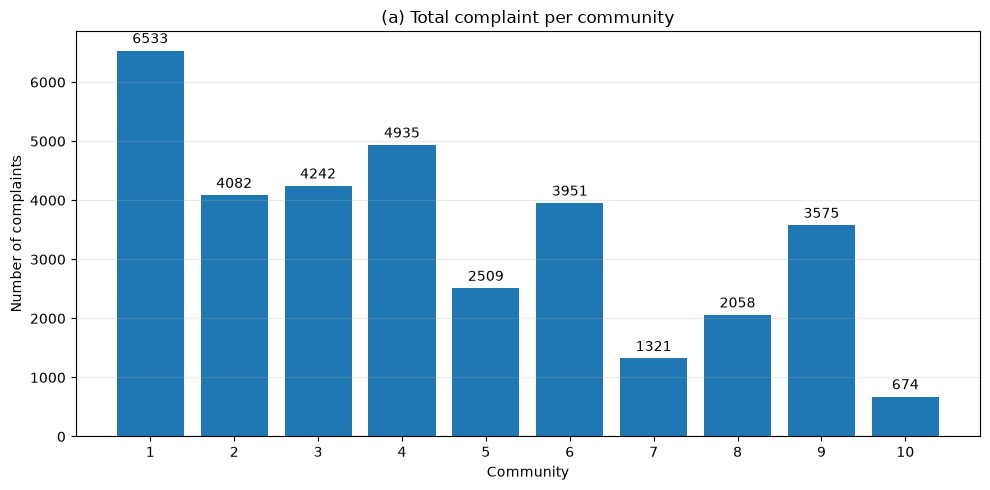

JUMLAH PENGADUAN SETIAP KOMUNITAS MENURUT TAHUN


tahun,2023,2024,2025
komunitas,,,
1,2174,2226,2133
2,678,1312,2092
3,1924,1431,887
4,2341,1623,971
5,1077,816,616
6,1210,1342,1399
7,719,396,206
8,921,729,408
9,1085,1316,1174


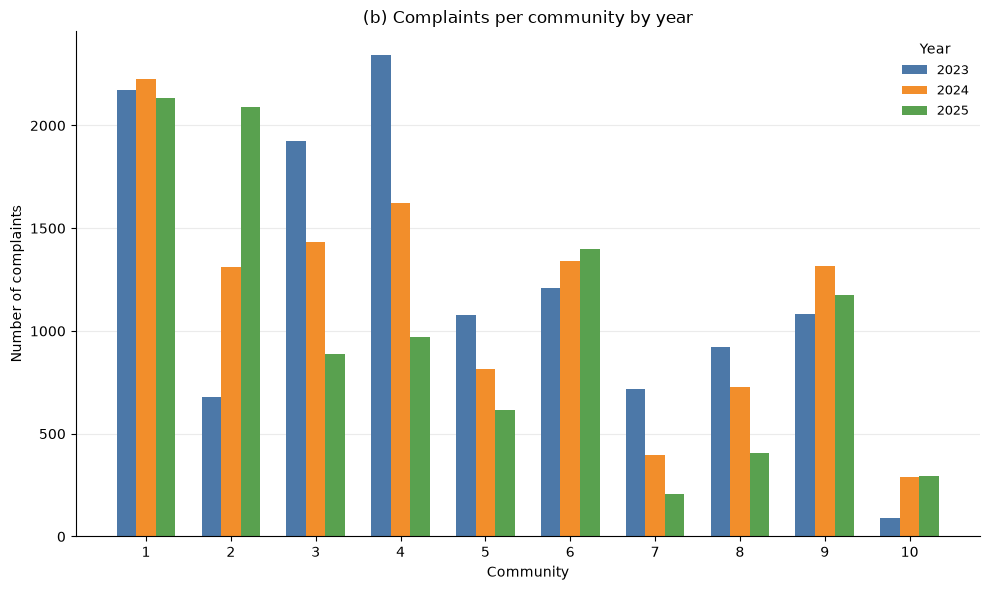

TOTAL PENGADUAN SELURUH KOMUNITAS MENURUT TAHUN


,tahun,jumlah_pengaduan
0,2023,12220
1,2024,11480
2,2025,10180


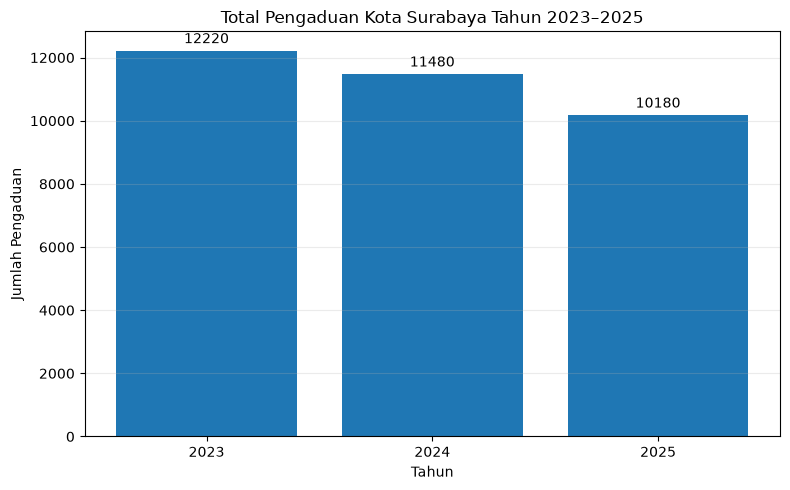

In [24]:
# JUMLAH PENGADUAN PADA 10 KOMUNITAS DAN MENURUT TAHUN
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Total pengaduan pada setiap komunitas
total_komunitas = (
    dfm.groupby("komunitas")
       .size()
       .reset_index(name="jumlah_pengaduan")
       .sort_values("komunitas")
)

print("TOTAL PENGADUAN PADA 10 KOMUNITAS")
display(total_komunitas)

# Grafik total pengaduan per komunitas
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    total_komunitas["komunitas"].astype(str),
    total_komunitas["jumlah_pengaduan"]
)

ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_xlabel("Community")
ax.set_ylabel("Number of complaints")
ax.set_title("(a) Total complaint per community")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "10_total_pengaduan_per_komunitas.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Jumlah pengaduan setiap komunitas menurut tahun
pengaduan_tahun = pd.crosstab(
    dfm["komunitas"],
    dfm["tahun"]
).sort_index()

print("JUMLAH PENGADUAN SETIAP KOMUNITAS MENURUT TAHUN")
display(pengaduan_tahun)

# Simpan tabel
pengaduan_tahun.to_csv(
    OUTPUT_DIR / "11_jumlah_pengaduan_komunitas_menurut_tahun.csv",
    encoding="utf-8-sig"
)


#pengaduan tiap tahun
pengaduan_tahun = pengaduan_tahun.sort_index()

pengaduan_tahun = pengaduan_tahun.reindex(
    sorted(pengaduan_tahun.columns),
    axis=1
)

communities = pengaduan_tahun.index.astype(str)
years = pengaduan_tahun.columns

x = np.arange(len(communities))
width = 0.23

colors = ["#4C78A8", "#F28E2B", "#59A14F"]

fig, ax = plt.subplots(figsize=(10, 6))

for i, year in enumerate(years):
    ax.bar(
        x + (i - (len(years) - 1) / 2) * width,
        pengaduan_tahun[year].values,
        width=width,
        label=str(year),
        color=colors[i % len(colors)]
    )

ax.set_title(
    "(b) Complaints per community by year",
    fontsize=12
)

ax.set_xlabel("Community", fontsize=10)
ax.set_ylabel("Number of complaints", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(communities)

ax.legend(
    title="Year",
    loc="upper right",
    frameon=False,
    fontsize=9
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "12_perbandingan_pengaduan_komunitas_barchart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.show()


# 4. Total pengaduan seluruh komunitas pada setiap tahun
total_tahunan = (
    dfm.groupby("tahun")
       .size()
       .reset_index(name="jumlah_pengaduan")
       .sort_values("tahun")
)

print("TOTAL PENGADUAN SELURUH KOMUNITAS MENURUT TAHUN")
display(total_tahunan)

# Grafik total tahunan
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    total_tahunan["tahun"].astype(str),
    total_tahunan["jumlah_pengaduan"]
)

ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Pengaduan")
ax.set_title("Total Pengaduan Kota Surabaya Tahun 2023–2025")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "13_total_pengaduan_menurut_tahun.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 5. Kecamatan dan kelurahan yang paling banyak berkontribusi

Tabel ini menunjukkan komposisi administratif. Karena komunitas dibentuk pada node kelurahan-tahun, satu kelurahan dapat muncul pada lebih dari satu komunitas di tahun yang berbeda.

In [25]:
district_rows = []
for c, g in dfm.groupby("komunitas", sort=True):
    vc = g["kecamatan"].value_counts()
    for rank, (name, n) in enumerate(vc.head(10).items(), start=1):
        district_rows.append({"komunitas": c, "peringkat": rank,
                              "kecamatan": name, "jumlah_pengaduan": int(n),
                              "proporsi_dalam_komunitas": n / len(g)})
district_profile = pd.DataFrame(district_rows)
district_profile.to_csv(OUTPUT_DIR / "06_district_profile_top10.csv", index=False, encoding="utf-8-sig")
display(district_profile)

,komunitas,peringkat,kecamatan,jumlah_pengaduan,proporsi_dalam_komunitas
0,1,1,Sukolilo,2213,0.338742
1,1,2,Rungkut,2160,0.330629
2,1,3,Mulyorejo,1170,0.179091
3,1,4,Gunung Anyar,687,0.105158
4,1,5,Tenggilis Mejoyo,210,0.032144
...,...,...,...,...,...
62,9,4,Wonokromo,157,0.043916
63,10,1,Semampir,231,0.342730
64,10,2,Simokerto,173,0.256677
65,10,3,Pabean Cantian,147,0.218101


## 6. Topik rinci dan instansi yang sering muncul

`topik` dan `instansi` adalah kategori yang sudah tersedia dalam data bersih. Gunakan keduanya untuk memperjelas interpretasi, tetapi periksa kembali contoh teks karena kategori administratif tidak selalu mencerminkan substansi keluhan secara sempurna.

In [26]:
detail_rows = []
for c, g in dfm.groupby("komunitas", sort=True):
    for col in ["topik", "instansi"]:
        if col in g.columns:
            for rank, (name, n) in enumerate(g[col].fillna("Tidak diketahui").value_counts().head(10).items(), start=1):
                detail_rows.append({"komunitas": c, "dimensi": col, "peringkat": rank,
                                    "label": name, "jumlah_pengaduan": int(n),
                                    "proporsi_dalam_komunitas": n / len(g)})
detail_profile = pd.DataFrame(detail_rows)
detail_profile.to_csv(OUTPUT_DIR / "07_detail_topik_instansi.csv", index=False, encoding="utf-8-sig")
display(detail_profile)

,komunitas,dimensi,peringkat,label,jumlah_pengaduan,proporsi_dalam_komunitas
0,1,topik,1,Jalan Rusak dan Berlubang,887,0.135772
1,1,topik,2,Pemangkasan/Perantingan Pohon,861,0.131792
2,1,topik,3,PJU,481,0.073626
3,1,topik,4,"Pembersihan Sampah Di Saluran/Sungai, Pedestrian, dan Jalan",234,0.035818
4,1,topik,5,Pelayanan PDAM,192,0.029389
...,...,...,...,...,...,...
195,10,instansi,6,Dinas Kependudukan dan Pencatatan Sipil,24,0.035608
196,10,instansi,7,Kecamatan Simokerto,24,0.035608
197,10,instansi,8,Kecamatan Semampir,20,0.029674
198,10,instansi,9,Dinas Kesehatan,18,0.026706


## 7. pemeriksaan kualitatif

Dua jenis sampel disiapkan untuk setiap komunitas:
1. **10 pengaduan acak** dari seluruh pengaduan komunitas, untuk melihat keragaman isi.
2. **5 pengaduan acak** dari kategori `kelompok_topik` dengan lift tertinggi yang memenuhi jumlah minimum, untuk memeriksa apakah kategori yang paling khas memang tampak dalam teks.

Pemilihan menggunakan `RANDOM_STATE` tetap dan hasil menyimpan `lokasi_key` serta `tahun` sebagai jejak audit internal. Sampel acak berasal dari pengaduan individual sehingga node/kelurahan dengan volume tinggi berpeluang menyumbang lebih banyak contoh; karena itu, contoh ini bersifat pemeriksaan kualitatif, bukan estimasi representatif. Jika kategori lift tertinggi tidak memenuhi jumlah minimum, status tersebut dicatat dan tidak dipaksakan.

In [27]:
RANDOM_STATE = 42
N_RANDOM_PER_COMMUNITY = 10
N_LIFT_SAMPLE_PER_COMMUNITY = 5
MIN_COUNT_FOR_LIFT_SAMPLE = 30

sample_rows = []
sample_status = []

for c in sorted(dfm["komunitas"].unique()):
    g = dfm[dfm["komunitas"] == c].copy()
    g = g[g["teks_embedding"].notna()]
    g = g[g["teks_embedding"].astype(str).str.strip().ne("")]

    # A. Sampel acak dari seluruh pengaduan komunitas
    take_random = min(N_RANDOM_PER_COMMUNITY, len(g))
    picked_random = g.iloc[0:0]
    if take_random:
        picked_random = g.sample(n=take_random, random_state=RANDOM_STATE + int(c))
        for _, r in picked_random.iterrows():
            sample_rows.append({
                "komunitas": int(c), "jenis_sampel": "acak_seluruh_komunitas",
                "kelompok_topik": r.get("kelompok_topik"),
                "lokasi_key": r.get("lokasi_key"), "tahun": r.get("tahun"),
                "teks_masked": r["teks_embedding"]
            })

    # B. Sampel dari topik dengan lift tertinggi yang memenuhi jumlah minimum
    cand = topic_long[
        (topic_long["komunitas"] == c) &
        (topic_long["jumlah_pengaduan"] >= MIN_COUNT_FOR_LIFT_SAMPLE)
    ].sort_values(["lift", "jumlah_pengaduan"], ascending=[False, False])

    if len(cand):
        selected_topic = cand.iloc[0]["kelompok_topik"]
        gt = g[g["kelompok_topik"] == selected_topic]
        take_lift = min(N_LIFT_SAMPLE_PER_COMMUNITY, len(gt))
    
        picked_lift = gt.sample(n=take_lift, random_state=RANDOM_STATE + 1000 + int(c))

    
        txt_random = set(picked_random["teks_embedding"].astype(str))
        dup_mask = picked_lift["teks_embedding"].astype(str).isin(txt_random)
        n_dup = int(dup_mask.sum())
        if n_dup:
            keep = picked_lift[~dup_mask]
            used = txt_random | set(keep["teks_embedding"].astype(str))
            pool = gt.drop(index=picked_lift.index)
            pool = pool[~pool["teks_embedding"].astype(str).isin(used)]
            pool = pool.drop_duplicates(subset="teks_embedding")
            extra = pool.sample(n=min(n_dup, len(pool)),
                                random_state=RANDOM_STATE + 2000 + int(c))
            picked_lift = pd.concat([keep, extra])

        for _, r in picked_lift.iterrows():
            sample_rows.append({
                "komunitas": int(c), "jenis_sampel": "topik_lift_tertinggi",
                "kelompok_topik": r.get("kelompok_topik"),
                "lokasi_key": r.get("lokasi_key"), "tahun": r.get("tahun"),
                "teks_masked": r["teks_embedding"]
            })
        sample_status.append({
            "komunitas": int(c), "topik_lift_tertinggi": selected_topic,
            "jumlah_kandidat": int(len(gt)), "jumlah_diambil": int(len(picked_lift)),
            "jumlah_diganti_karena_duplikat": n_dup, "status": "tersedia"
        })
    else:
        sample_status.append({
            "komunitas": int(c), "topik_lift_tertinggi": None,
            "jumlah_kandidat": 0, "jumlah_diambil": 0,
            "jumlah_diganti_karena_duplikat": 0,
            "status": f"tidak ada kategori dengan minimal {MIN_COUNT_FOR_LIFT_SAMPLE} pengaduan"
        })

qual_samples = pd.DataFrame(sample_rows)
qual_sample_status = pd.DataFrame(sample_status)
qual_samples.to_csv(OUTPUT_DIR / "08_qualitative_samples_internal.csv",
                    index=False, encoding="utf-8-sig")
qual_sample_status.to_csv(OUTPUT_DIR / "08b_qualitative_sample_status.csv",
                          index=False, encoding="utf-8-sig")
display(qual_sample_status)
display(qual_samples.groupby(["komunitas", "jenis_sampel"]).size().unstack(fill_value=0))
display(qual_samples.head(20))

,komunitas,topik_lift_tertinggi,jumlah_kandidat,jumlah_diambil,jumlah_diganti_karena_duplikat,status
0,1,Perumahan & Pertanahan,249,5,0,tersedia
1,2,Infrastruktur Jalan & Saluran,801,5,0,tersedia
2,3,Pendidikan,213,5,0,tersedia
3,4,Sosial,365,5,0,tersedia
4,5,Kesehatan,185,5,0,tersedia
5,6,Perhubungan & Lalu Lintas,654,5,0,tersedia
6,7,Sosial,117,5,0,tersedia
7,8,Sosial,151,5,0,tersedia
8,9,Penerangan Jalan & Traffic Light,610,5,0,tersedia
9,10,Perhubungan & Lalu Lintas,103,5,1,tersedia


jenis_sampel,acak_seluruh_komunitas,topik_lift_tertinggi
komunitas,,
1,10,5
2,10,5
3,10,5
4,10,5
5,10,5
6,10,5
7,10,5
8,10,5
9,10,5


,komunitas,jenis_sampel,kelompok_topik,lokasi_key,tahun,teks_masked
0,1,acak_seluruh_komunitas,Perhubungan & Lalu Lintas,penjaringan sari|rungkut,2025,Halte Medokan Asri Tengah A terhalang oleh mobil yang terparkir
1,1,acak_seluruh_komunitas,Kebersihan & Lingkungan,kalisari|mulyorejo,2023,assalamualaikum wr wb mohon ijin melaporkan untuk aliran sungai wilayah kami tersumbat oleh sampah mohon kepada pihak terkait menindak lanjuti masalah tsb karena sebentar lagi ...
2,1,acak_seluruh_komunitas,Banjir & Drainase,gunung anyar tambak|gununganyar,2025,"Banjir di perumahan Wisma Indah 2 Blok K3 khususnya karena adanya perumahan baru Alana Wisma Indah dan Jalan depan Wisma Tirta Agung yang tinggi, untuk ukuran Wisma Indah 2 jal..."
3,1,acak_seluruh_komunitas,Pendidikan,medokan semampir|sukolilo,2023,"penanganan siswa inklusi SMP 30 tidak berpihak terhadap siswa,lebih mementingkan penilaian/kurikulum bagi guru yg mengajar.siswa sudah sangat nyaman belajar dengan teman2 regul..."
4,1,acak_seluruh_komunitas,Infrastruktur Jalan & Saluran,penjaringan sari|rungkut,2024,jaĺan berlubang dan terkelupas di Penjaringan Asri IX PS J 17 Kel Penjaringan Sari Kec Rungkut Surabaya
5,1,acak_seluruh_komunitas,Kebersihan & Lingkungan,semolowaru|sukolilo,2025,mohon bantuannya untuk perantingan/pemangkasan pohon mangga yg mengganggu masjid
6,1,acak_seluruh_komunitas,Perhubungan & Lalu Lintas,menur pumpungan|sukolilo,2025,"Semalem saya di wedrink nginden semolo.Disitu ada jukir,dimana rompi merah dikaitkan di pohon/pagar.Kemudian saya memberikan uang parkir 2ribu,akan tetapi jukir tsb meminta 3ri..."
7,1,acak_seluruh_komunitas,Kebersihan & Lingkungan,gunung anyar tambak|gununganyar,2025,"terkait keluhan kami soal permintaan lampiran hasil lab dari surat DLH, bila tidak dilampirkan, kami menganggap persoalan belumlah selesai, keputusan patut dipertanyakan karena..."
8,1,acak_seluruh_komunitas,Kebersihan & Lingkungan,manyar sabrangan|mulyorejo,2024,tanaman ketepeng sudah tinggi dan dekat dengan kabel telkom dan PLN
9,1,acak_seluruh_komunitas,Pelayanan Kewilayahan,kalijudan|mulyorejo,2023,saya salah satu warga perumahan puri kalijudan dg ini melakukan pengaduan kpd dinas terkait unt tdk memberikan ijin penutupan jln kalijudan mulai dr puskesmas kalijudan hingga ...


## 8. Peta titik kelurahan menurut komunitas

Peta berikut adalah peta titik centroid kelurahan, bukan peta batas poligon administratif. Satu titik merepresentasikan satu node kelurahan-tahun; peta dibuat terpisah per tahun.

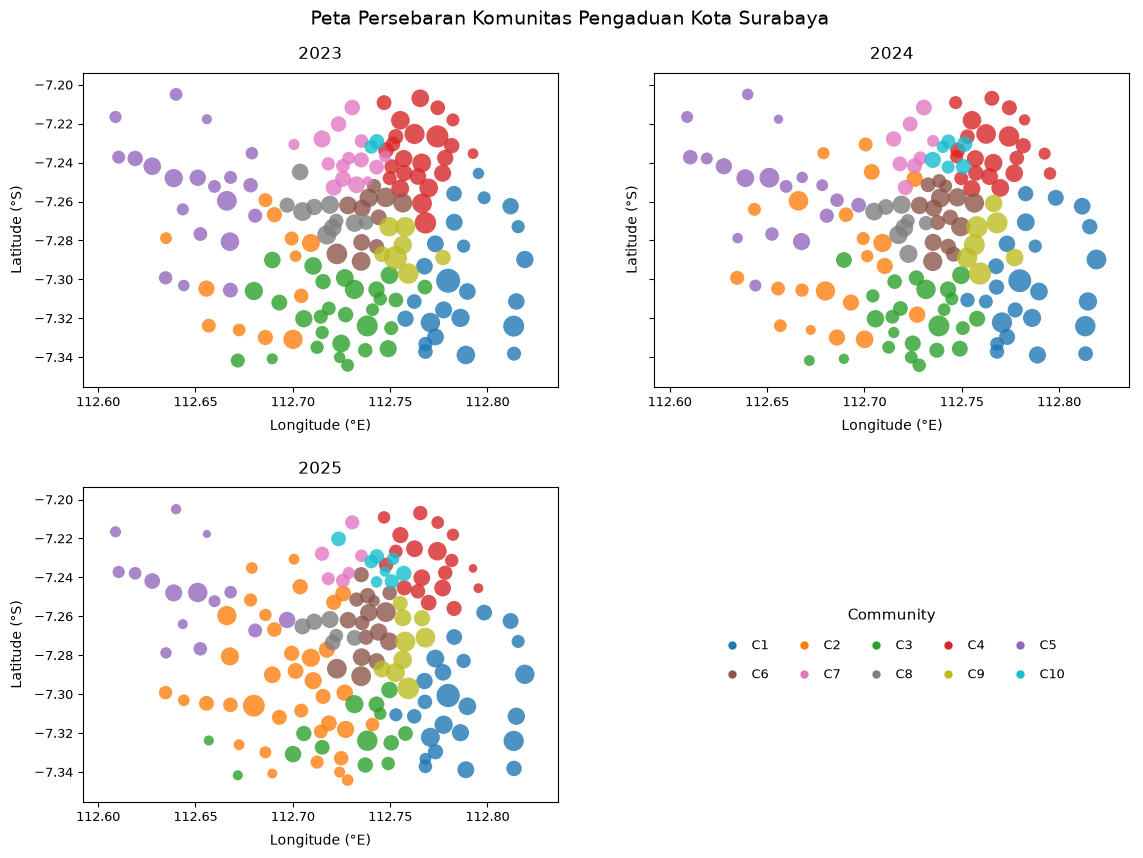

In [34]:

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.lines import Line2D

required_cols = [
    "kelurahan",
    "tahun",
    "komunitas",
    "lat_kelurahan",
    "lon_kelurahan",
    "n_pengaduan"
]

missing_cols = [c for c in required_cols if c not in nodes.columns]

assert not missing_cols, (
    f"Kolom berikut tidak ditemukan pada nodes: {missing_cols}"
)

map_df = nodes[required_cols].copy()

map_df = map_df.dropna(
    subset=["lat_kelurahan", "lon_kelurahan", "komunitas"]
)

communities = sorted(
    map_df["komunitas"].unique(),
    key=lambda x: int(str(x).replace("C", "").replace("c", ""))
)

cmap = plt.get_cmap("tab10", len(communities))

color_map = {
    c: cmap(i)
    for i, c in enumerate(communities)
}

min_size = 35
max_size = 300

complaint_count = (
    map_df["n_pengaduan"]
    .fillna(0)
    .clip(lower=0)
)

sqrt_count = np.sqrt(complaint_count)

if sqrt_count.max() > sqrt_count.min():
    map_df["ukuran_titik"] = (
        min_size
        + (
            (sqrt_count - sqrt_count.min())
            / (sqrt_count.max() - sqrt_count.min())
        ) * (max_size - min_size)
    )
else:
    map_df["ukuran_titik"] = 100

lon_min = map_df["lon_kelurahan"].min()
lon_max = map_df["lon_kelurahan"].max()

lat_min = map_df["lat_kelurahan"].min()
lat_max = map_df["lat_kelurahan"].max()

lon_margin = (lon_max - lon_min) * 0.08
lat_margin = (lat_max - lat_min) * 0.08

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

plot_axes = [
    axes[0, 0],
    axes[0, 1],
    axes[1, 0]
]

for ax, year in zip(plot_axes, years):

    year_data = map_df[
        map_df["tahun"] == year
    ]

    for c in communities:

        subset = year_data[
            year_data["komunitas"] == c
        ]

        if subset.empty:
            continue

        ax.scatter(
            subset["lon_kelurahan"],
            subset["lat_kelurahan"],
            s=subset["ukuran_titik"],
            color=color_map[c],
            alpha=0.80,
            edgecolors="none"
        )

    ax.set_title(
        str(year),
        fontsize=12,
        pad=10
    )

    ax.set_xlabel(
        "Longitude (°E)",
        fontsize=10,
        labelpad=7
    )

    ax.set_ylabel(
        "Latitude (°S)",
        fontsize=10,
        labelpad=7
    )

    ax.set_xlim(
        lon_min - lon_margin,
        lon_max + lon_margin
    )

    ax.set_ylim(
        lat_min - lat_margin,
        lat_max + lat_margin
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        labelbottom=True
    )

    ax.grid(False)

axes[1, 1].axis("off")



legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=color_map[c],
        markeredgecolor="none",
        markersize=6,
        linestyle="None",
        label=f"C{c}"
    )
    for c in communities
]

ncol = 5
nrow = int(np.ceil(len(legend_elements) / ncol))

legend_order = [
    legend_elements[i]
    for col in range(ncol)
    for i in [col, col + ncol]
    if i < len(legend_elements)
]

axes[1, 1].legend(
    handles=legend_order,
    title="Community",
    loc="center",
    ncol=5,
    frameon=False,
    fontsize=9,
    title_fontsize=11,
    columnspacing=1.8,
    handletextpad=0.6,
    labelspacing=1.2
)


fig.suptitle(
    "Peta Persebaran Komunitas Pengaduan Kota Surabaya",
    fontsize=14,
    y=0.97
)

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.09,
    top=0.90,
    wspace=0.18,
    hspace=0.32
)

plt.savefig(
    OUTPUT_DIR / "09_map_community_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Ringkasan interpretasi awal

Tabel berikut menggabungkan tiga topik teratas dan tiga kecamatan teratas sebagai bahan awal interpretasi.

In [ ]:
MIN_COUNT_FOR_LIFT_SIGNATURE = 30
ALPHA_N2 = 0.05

n2 = pd.read_csv(N2_PATH)[["komunitas", "q_BH_N2"]].copy()
n2["komunitas"] = n2["komunitas"].astype(int)
n2["status_uji_pembeda_N2"] = (
    np.where(n2["q_BH_N2"] < ALPHA_N2, "Signifikan", "Tidak signifikan")
    + " (q=" + n2["q_BH_N2"].round(3).astype(str) + ")")
n2_status = n2.set_index("komunitas")["status_uji_pembeda_N2"].to_dict()
_missing = sorted(set(map(int, dfm["komunitas"].unique())) - set(n2_status))
assert not _missing, f"Komunitas {_missing} tidak ada di file uji N2: {N2_PATH}"

interpretation_rows = []
for c in sorted(dfm["komunitas"].unique()):
    g = dfm[dfm["komunitas"] == c]
    tops = g["kelompok_topik"].value_counts().head(3)
    districts = g["kecamatan"].value_counts().head(3)
    lift_candidates = topic_long[
        (topic_long["komunitas"] == c) &
        (topic_long["jumlah_pengaduan"] >= MIN_COUNT_FOR_LIFT_SIGNATURE)
    ].sort_values("lift", ascending=False)
    top_lift = lift_candidates.iloc[0] if len(lift_candidates) else None
    interpretation_rows.append({
        "komunitas": int(c),
        "n_pengaduan": len(g),
        "topik_terbanyak_deskriptif": " | ".join(
            f"{k} ({v/len(g):.1%})" for k, v in tops.items()),
        "topik_lift_tertinggi": (
            f"{top_lift['kelompok_topik']} (lift {top_lift['lift']:.2f}; "
            f"{int(top_lift['jumlah_pengaduan'])} aduan)"
            if top_lift is not None else "Tidak ada kategori yang memenuhi batas minimum"),
        "kecamatan_utama_deskriptif": " | ".join(
            f"{k} ({v/len(g):.1%})" for k, v in districts.items()),
        "status_uji_pembeda_N2": n2_status[int(c)],
        "interpretasi_peneliti": "",
        "alasan_penamaan_tema": ""
    })
interpretation_draft = pd.DataFrame(interpretation_rows)
interpretation_draft.to_csv(OUTPUT_DIR / "10_interpretation_worksheet.csv",
                            index=False, encoding="utf-8-sig")
display(interpretation_draft)

,komunitas,n_pengaduan,topik_terbanyak_deskriptif,topik_lift_tertinggi,kecamatan_utama_deskriptif,status_uji_pembeda_N2,interpretasi_peneliti,alasan_penamaan_tema
0,1,6533,Kebersihan & Lingkungan (22.9%) | Infrastruktur Jalan & Saluran (19.1%) | Pelayanan Kewilayahan (9.4%),Perumahan & Pertanahan (lift 1.54; 249 aduan),Sukolilo (33.9%) | Rungkut (33.1%) | Mulyorejo (17.9%),Signifikan (q=0.044),,
1,2,4082,Infrastruktur Jalan & Saluran (19.6%) | Kebersihan & Lingkungan (15.1%) | Perhubungan & Lalu Lintas (11.7%),Infrastruktur Jalan & Saluran (lift 1.58; 801 aduan),Wiyung (18.5%) | Dukuh Pakis (16.1%) | Lakarsantri (11.1%),Signifikan (q=0.003),,
2,3,4242,Kebersihan & Lingkungan (16.5%) | Pelayanan Kewilayahan (13.7%) | Perhubungan & Lalu Lintas (9.1%),Pendidikan (lift 1.38; 213 aduan),Wonokromo (25.8%) | Wonocolo (22.7%) | Tenggilis Mejoyo (10.7%),Signifikan (q=0.023),,
3,4,4935,Pelayanan Kewilayahan (16.1%) | Kebersihan & Lingkungan (11.8%) | Kependudukan & Catatan Sipil (9.4%),Sosial (lift 2.08; 365 aduan),Tambaksari (34.0%) | Kenjeran (27.2%) | Simokerto (12.8%),Signifikan (q=0.0),,
4,5,2509,Pelayanan Kewilayahan (14.2%) | Kebersihan & Lingkungan (13.5%) | Infrastruktur Jalan & Saluran (10.8%),Kesehatan (lift 1.42; 185 aduan),Benowo (31.8%) | Tandes (21.4%) | Pakal (20.2%),Tidak signifikan (q=0.746),,
5,6,3951,Kebersihan & Lingkungan (18.1%) | Perhubungan & Lalu Lintas (16.6%) | Infrastruktur Jalan & Saluran (12.2%),Perhubungan & Lalu Lintas (lift 1.81; 654 aduan),Genteng (29.8%) | Tegalsari (20.5%) | Sawahan (16.3%),Signifikan (q=0.0),,
6,7,1321,Pelayanan Kewilayahan (16.7%) | Kebersihan & Lingkungan (11.6%) | Lainnya (9.2%),Sosial (lift 2.49; 117 aduan),Krembangan (42.5%) | Bubutan (31.6%) | Pabean Cantian (23.2%),Signifikan (q=0.0),,
7,8,2058,Pelayanan Kewilayahan (16.6%) | Kebersihan & Lingkungan (11.6%) | Lainnya (8.8%),Sosial (lift 2.06; 151 aduan),Sawahan (54.6%) | Sukomanunggal (28.7%) | Tegalsari (12.8%),Signifikan (q=0.0),,
8,9,3575,Kebersihan & Lingkungan (25.9%) | Penerangan Jalan & Traffic Light (17.1%) | Infrastruktur Jalan & Saluran (11.2%),Penerangan Jalan & Traffic Light (lift 1.86; 610 aduan),Gubeng (82.0%) | Tambaksari (9.0%) | Sukolilo (4.6%),Signifikan (q=0.016),,
9,10,674,Perhubungan & Lalu Lintas (15.3%) | Kebersihan & Lingkungan (13.4%) | Pelayanan Kewilayahan (12.3%),Perhubungan & Lalu Lintas (lift 1.67; 103 aduan),Semampir (34.3%) | Simokerto (25.7%) | Pabean Cantian (21.8%),Tidak signifikan (q=0.311),,


In [ ]:
MIN_COUNT_FOR_LIFT_SIGNATURE = 30

summary_rows = []
for c in sorted(dfm["komunitas"].unique()):
    g = dfm[dfm["komunitas"] == c]
    n_c = len(g)

    # Topik dominan berdasarkan jumlah pengaduan
    vc_topic = g["kelompok_topik"].value_counts()
    dominant_topic = vc_topic.index[0]
    dominant_n = int(vc_topic.iloc[0])
    dominant_share = dominant_n / n_c

    # Topik pembeda: lift tertinggi dengan jumlah minimal 30 aduan
    candidates = topic_long[
        (topic_long["komunitas"] == c) &
        (topic_long["jumlah_pengaduan"] >= MIN_COUNT_FOR_LIFT_SIGNATURE)
    ].sort_values(["lift", "jumlah_pengaduan"], ascending=False)
    if len(candidates):
        distinctive = candidates.iloc[0]
        distinctive_topic = distinctive["kelompok_topik"]
        distinctive_lift = float(distinctive["lift"])
        distinctive_n = int(distinctive["jumlah_pengaduan"])
        distinctive_share = float(distinctive["share_komunitas"])
    else:
        distinctive_topic, distinctive_lift = "Tidak tersedia", np.nan
        distinctive_n, distinctive_share = 0, np.nan

    # Kecamatan dengan jumlah pengaduan terbanyak
    vc_dist = g["kecamatan"].value_counts()
    top_district = vc_dist.index[0]
    top_district_n = int(vc_dist.iloc[0])
    top_district_share = top_district_n / n_c

    # Volume tahunan, dihitung dari pengaduan yang tercatat
    y23 = int((g["tahun"] == 2023).sum())
    y24 = int((g["tahun"] == 2024).sum())
    y25 = int((g["tahun"] == 2025).sum())
    change_pct = ((y25 / y23) - 1) * 100 if y23 > 0 else np.nan

    summary_rows.append({
        "komunitas": int(c),
        "jumlah_node": int((nodes["komunitas"] == c).sum()),
        "jumlah_pengaduan": n_c,
        "topik_terbanyak_deskriptif": dominant_topic,
        "topik_terbanyak_n": dominant_n,
        "topik_terbanyak_share": dominant_share,
        "topik_lift_tertinggi": distinctive_topic,
        "topik_lift_tertinggi_n": distinctive_n,
        "topik_lift_tertinggi_share": distinctive_share,
        "topik_lift_tertinggi_value": distinctive_lift,
        "kecamatan_teratas": top_district,
        "kecamatan_teratas_n": top_district_n,
        "kecamatan_teratas_share": top_district_share,
        "pengaduan_2023": y23,
        "pengaduan_2024": y24,
        "pengaduan_2025": y25,
        "perubahan_volume_2023_2025_pct": change_pct
    })

article_summary = pd.DataFrame(summary_rows)

article_summary["status_uji_pembeda_N2"] = article_summary["komunitas"].map(n2_status)
_ci = (lift_bootstrap_ci
       .rename(columns={"kelompok_topik": "topik_lift_tertinggi",
                        "ci95_bawah": "lift_ci95_bawah", "ci95_atas": "lift_ci95_atas"})
       [["komunitas", "topik_lift_tertinggi", "lift_ci95_bawah", "lift_ci95_atas"]])
article_summary = article_summary.merge(_ci, on=["komunitas", "topik_lift_tertinggi"], how="left")
article_summary["boleh_diberi_nama_tematik"] = (
    article_summary["status_uji_pembeda_N2"].str.startswith("Signifikan"))

article_summary.to_csv(OUTPUT_DIR / "11_article_ready_community_summary.csv",
                       index=False, encoding="utf-8-sig")
display(article_summary.round(3))

assert article_summary["jumlah_pengaduan"].sum() == len(dfm)
assert article_summary["komunitas"].nunique() == nodes["komunitas"].nunique()
assert len(article_summary) == 10
assert article_summary["status_uji_pembeda_N2"].notna().all()
print("PASS: ringkasan mencakup seluruh 10 komunitas dan", f"{len(dfm):,}", "pengaduan.")
print("File tersimpan:", OUTPUT_DIR / "11_article_ready_community_summary.csv")


,komunitas,jumlah_node,jumlah_pengaduan,topik_terbanyak_deskriptif,topik_terbanyak_n,topik_terbanyak_share,topik_lift_tertinggi,topik_lift_tertinggi_n,topik_lift_tertinggi_share,topik_lift_tertinggi_value,kecamatan_teratas,kecamatan_teratas_n,kecamatan_teratas_share,pengaduan_2023,pengaduan_2024,pengaduan_2025,perubahan_volume_2023_2025_pct,status_uji_pembeda_N2,lift_ci95_bawah,lift_ci95_atas,boleh_diberi_nama_tematik
0,1,72,6533,Kebersihan & Lingkungan,1498,0.229,Perumahan & Pertanahan,249,0.038,1.545,Sukolilo,2213,0.339,2174,2226,2133,-1.886,Signifikan (q=0.044),1.071,2.111,True
1,2,69,4082,Infrastruktur Jalan & Saluran,801,0.196,Infrastruktur Jalan & Saluran,801,0.196,1.578,Wiyung,757,0.185,678,1312,2092,208.555,Signifikan (q=0.003),1.343,1.887,True
2,3,66,4242,Kebersihan & Lingkungan,702,0.165,Pendidikan,213,0.050,1.384,Wonokromo,1095,0.258,1924,1431,887,-53.898,Signifikan (q=0.023),1.028,1.795,True
3,4,65,4935,Pelayanan Kewilayahan,795,0.161,Sosial,365,0.074,2.081,Tambaksari,1678,0.340,2341,1623,971,-58.522,Signifikan (q=0.0),1.714,2.527,True
4,5,53,2509,Pelayanan Kewilayahan,357,0.142,Kesehatan,185,0.074,1.419,Benowo,797,0.318,1077,816,616,-42.804,Tidak signifikan (q=0.746),1.059,1.891,False
5,6,42,3951,Kebersihan & Lingkungan,716,0.181,Perhubungan & Lalu Lintas,654,0.166,1.813,Genteng,1177,0.298,1210,1342,1399,15.620,Signifikan (q=0.0),1.511,2.194,True
6,7,29,1321,Pelayanan Kewilayahan,221,0.167,Sosial,117,0.089,2.492,Krembangan,561,0.425,719,396,206,-71.349,Signifikan (q=0.0),1.818,3.471,True
7,8,24,2058,Pelayanan Kewilayahan,342,0.166,Sosial,151,0.073,2.065,Sawahan,1123,0.546,921,729,408,-55.700,Signifikan (q=0.0),1.339,2.963,True
8,9,23,3575,Kebersihan & Lingkungan,926,0.259,Penerangan Jalan & Traffic Light,610,0.171,1.860,Gubeng,2931,0.820,1085,1316,1174,8.203,Signifikan (q=0.016),1.482,2.320,True
9,10,16,674,Perhubungan & Lalu Lintas,103,0.153,Perhubungan & Lalu Lintas,103,0.153,1.673,Semampir,231,0.343,91,289,294,223.077,Tidak signifikan (q=0.311),1.274,2.060,False


PASS: ringkasan mencakup seluruh 10 komunitas dan 33,880 pengaduan.
File tersimpan: c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\community_profiling\11_article_ready_community_summary.csv
